# Class 3 — Semantic Networks: Categories, Relations, and Specificity

**Instructor working notebook** · Data Science Master's · 100-minute seminar companion

This notebook follows the course syllabus: build a typed semantic network, distinguish taxonomic relations from other relations, calculate two simple specificity estimates, visualize the network, and test how missing or added edges change the results.

**Teaching boundary:** the graph is a transparent computational model of selected relations. It is not a complete model of meaning, a universal ontology, or direct evidence about human cognition.

## Suggested seminar rhythm (100 minutes)
- 0–10: inspect the data and label relation types
- 10–25: separate category, component, and function relations
- 25–40: build and visualize the taxonomy and full typed network
- 40–60: calculate and compare specificity estimates
- 60–70: compare WordNet and FrameNet-style resources
- 70–85: perturb the graph and inspect changed scores
- 85–95: team extension
- 95–100: exit ticket and submission instructions

## 0. What students should understand before coding

A **semantic network** represents concepts as nodes and meaningful relations as edges. Not all edges mean the same thing:

- `is_a`: a category relation, directed from a broader category to a narrower one (e.g., `vehicle → car`).
- `part_of`: a component relation (e.g., `wheel → bicycle`).
- `used_for`: a functional relation (e.g., `cup → holding_liquid`).
- `associated_with`, `supports`, or `constrains`: other context-dependent relations.

For this class, calculate taxonomic specificity using only `is_a` edges. If `used_for` or `associated_with` edges are mixed into the category hierarchy, the depth score becomes difficult to interpret.

**Connection to the embodied approach:** concepts are not treated only as isolated dictionary labels. Their use can depend on what entities afford, how they participate in events, what roles they play, and how they relate to goals and actions. A graph can encode some of those relations, but the graph itself does not perceive, act, or prove that a system understands a concept.

In [1]:
from pathlib import Path
import sys, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

print("Python:", sys.version.split()[0])
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.5
NetworkX: 3.6.1
Pandas: 2.2.3
NumPy: 2.3.5


In [2]:
# Find the data directory whether Jupyter was launched from the kit root or notebooks/.
candidates = [Path("data"), Path("../data"), Path("../../data")]
DATA_DIR = next((p.resolve() for p in candidates if (p / "concepts.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find data/concepts.csv. Run Jupyter from the kit folder or notebooks/.")
print("Using data:", DATA_DIR)

Using data: /mnt/data/Class_03_Instructor_Starter_Kit/data


In [3]:
concepts = pd.read_csv(DATA_DIR / "concepts.csv")
edges = pd.read_csv(DATA_DIR / "semantic_edges.csv")
wordnet_targets = pd.read_csv(DATA_DIR / "wordnet_lookup_targets.csv")
framenet_examples = pd.read_csv(DATA_DIR / "framenet_teaching_examples.csv")

print("Concepts:", concepts.shape)
print("Edges:", edges.shape)
display(concepts.head(8))
display(edges.head(8))

Concepts: (47, 5)
Edges: (59, 5)


,id,label,definition,domain,example
0,concept,Concept,Root category for the teaching taxonomy.,meta,A concept can be represented by several typed ...
1,physical_concept,Physical concept,A concept primarily grounded in physical entit...,physical,A cup is a physical concept.
2,artifact,Artifact,A human-made object.,physical,A cup is an artifact.
3,container,Container,An artifact whose function includes holding or...,physical,A cup can contain liquid.
4,cup,Cup,A drinking vessel with an open top.,physical,She put the cup on the table.
5,bottle,Bottle,A container typically used to store or carry l...,physical,The bottle contains water.
6,drinking_vessel,Drinking vessel,An object designed for drinking from.,physical,A cup is a drinking vessel.
7,vehicle,Vehicle,An artifact used to transport people or goods.,physical,The vehicle stopped.


,source,target,relation,provenance,confidence
0,concept,physical_concept,is_a,instructor_curated_taxonomy,high
1,physical_concept,artifact,is_a,instructor_curated_taxonomy,high
2,artifact,container,is_a,instructor_curated_taxonomy,high
3,container,cup,is_a,instructor_curated_taxonomy,high
4,container,bottle,is_a,instructor_curated_taxonomy,high
5,artifact,drinking_vessel,is_a,instructor_curated_taxonomy,high
6,drinking_vessel,cup,is_a,instructor_curated_taxonomy,high
7,artifact,vehicle,is_a,instructor_curated_taxonomy,high


## 1. Data checks and relation inventory

Before analyzing a graph, check that every edge endpoint exists in the concept table and inspect relation types. This is basic data validation: a dangling edge can silently distort a network or cause a visualization to omit a node.

In [4]:
concept_ids = set(concepts["id"])
missing = (set(edges["source"]) | set(edges["target"])) - concept_ids
assert not missing, f"Edges refer to missing concepts: {sorted(missing)}"
assert concepts["id"].is_unique, "Concept IDs must be unique."

print("Relation counts:")
display(edges["relation"].value_counts().rename_axis("relation").to_frame("count"))
print("Concept domains:")
display(concepts["domain"].value_counts().rename_axis("domain").to_frame("count"))

Relation counts:


,count
relation,
is_a,47
associated_with,4
part_of,3
used_for,3
supports,1
constrains,1


Concept domains:


,count
domain,
abstract,21
physical,20
spatial,4
meta,1
social,1


**Instructor prompt:** Why must we separate `is_a` from `part_of` and `used_for`?

**Expected answer:** `vehicle → car` means a car is a type of vehicle. `wheel → bicycle` means a wheel is a component of a bicycle. `cup → holding_liquid` means a cup can serve a function. Treating all three as category edges would incorrectly imply that a wheel is a kind of bicycle or that holding liquid is a kind of cup.

In [5]:
# Build two graph views: the complete typed network and the category-only DAG.
G = nx.DiGraph()
for row in concepts.itertuples(index=False):
    G.add_node(row.id, label=row.label, domain=row.domain, definition=row.definition)
for row in edges.itertuples(index=False):
    G.add_edge(row.source, row.target, relation=row.relation,
               provenance=row.provenance, confidence=row.confidence)

T = nx.DiGraph((u, v) for u, v, d in G.edges(data=True) if d["relation"] == "is_a")
assert nx.is_directed_acyclic_graph(T), "The is_a subgraph should be acyclic for this taxonomy exercise."
ROOT = "concept"
assert ROOT in T and all(n in nx.descendants(T, ROOT) or n == ROOT for n in T.nodes),        "Every taxonomy node should be reachable from the root in the teaching dataset."

print(f"Full network: {G.number_of_nodes()} nodes, {G.number_of_edges()} typed edges")
print(f"Taxonomy: {T.number_of_nodes()} nodes, {T.number_of_edges()} is_a edges")

Full network: 47 nodes, 59 typed edges
Taxonomy: 47 nodes, 47 is_a edges


## 2. Visualize the category hierarchy

A hierarchical layout makes the broad-to-specific direction visible. Multiple inheritance is allowed in a directed acyclic graph: for instance, the teaching dataset gives `cup` two parents (`container` and `drinking_vessel`). This is one reason a taxonomy is not always a simple tree.

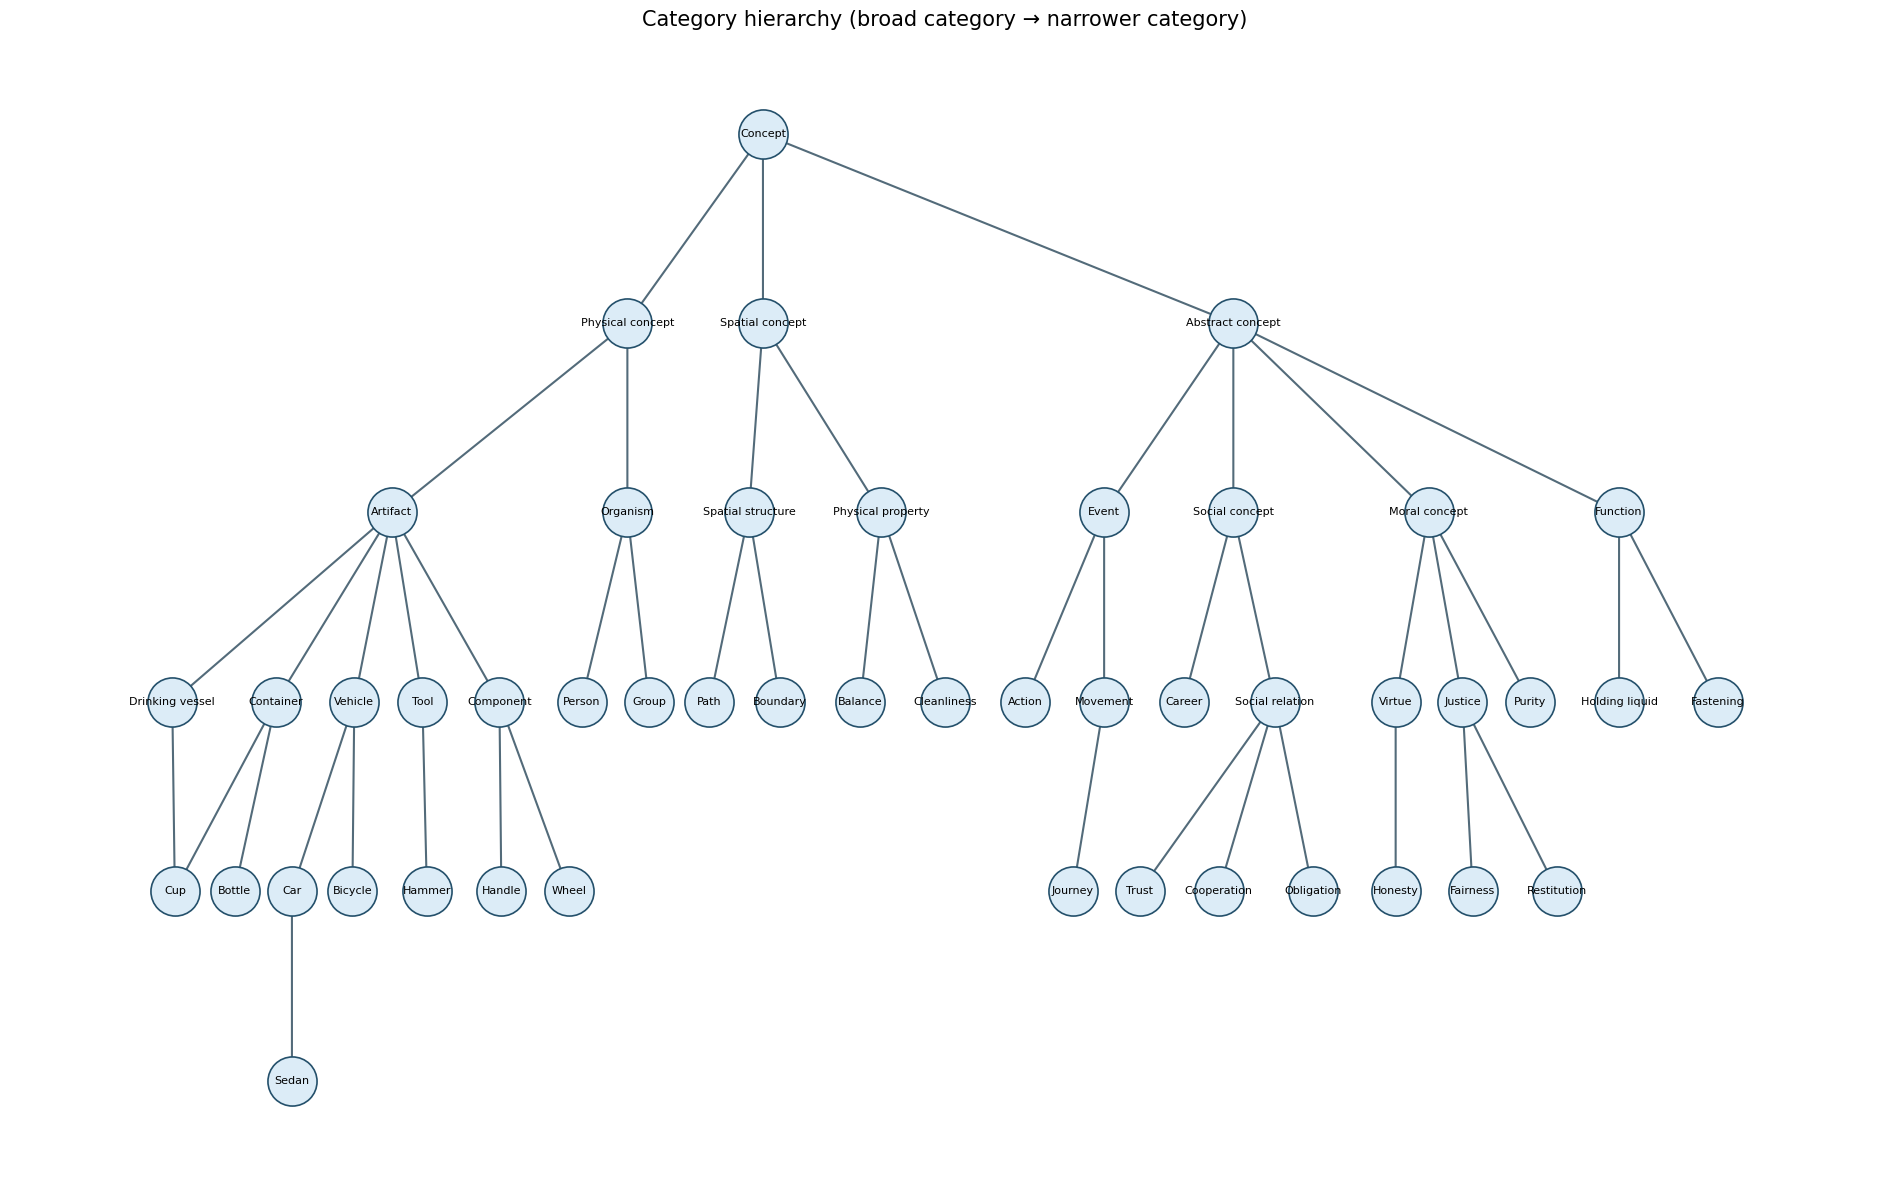

In [6]:
def shortest_depths(dag, root):
    """Shortest number of is_a steps from root to each reachable node."""
    return dict(nx.single_source_shortest_path_length(dag, root))

def layered_positions(dag, root):
    depths = shortest_depths(dag, root)
    layers = {}
    for node, depth in depths.items():
        layers.setdefault(depth, []).append(node)
    pos = {}
    for depth, nodes in layers.items():
        nodes = sorted(nodes)
        xs = np.linspace(-1, 1, len(nodes)) if len(nodes) > 1 else [0]
        for x, node in zip(xs, nodes):
            pos[node] = (float(x), -float(depth))
    return pos

try:
    # Graphviz 'dot' gives a clearer top-to-bottom hierarchy when installed.
    pos = nx.nx_agraph.graphviz_layout(T, prog="dot", args="-Granksep=0.9 -Gnodesep=0.35")
except Exception:
    pos = layered_positions(T, ROOT)
labels = {n: G.nodes[n]["label"] for n in T.nodes}
plt.figure(figsize=(19, 12))
nx.draw_networkx_nodes(T, pos, node_size=1250, node_color="#dcecf7", edgecolors="#24506b", linewidths=1.2)
nx.draw_networkx_labels(T, pos, labels=labels, font_size=8)
nx.draw_networkx_edges(T, pos, arrows=True, arrowstyle="-|>", arrowsize=13, edge_color="#536b7a", width=1.5)
plt.title("Category hierarchy (broad category → narrower category)", fontsize=15)
plt.axis("off"); plt.tight_layout(); plt.show()

**Discuss:** What does the diagram make easy to see? What does it hide?

It makes category depth and multiple parents visible. It does not show the full context in which a concept is used, the strength of every association, metaphorical interpretation, or whether a relation is culturally or contextually appropriate. The graph is also only as complete as its data and annotation rules.

## 3. Visualize a compact typed subnetwork

This compact object/function subnetwork includes category, component, and function links. Use edge labels and a legend rather than assuming all relations are interchangeable. A spring layout is useful for exploration but should not be interpreted as a semantic geometry: node proximity is a layout choice, not a measured similarity.

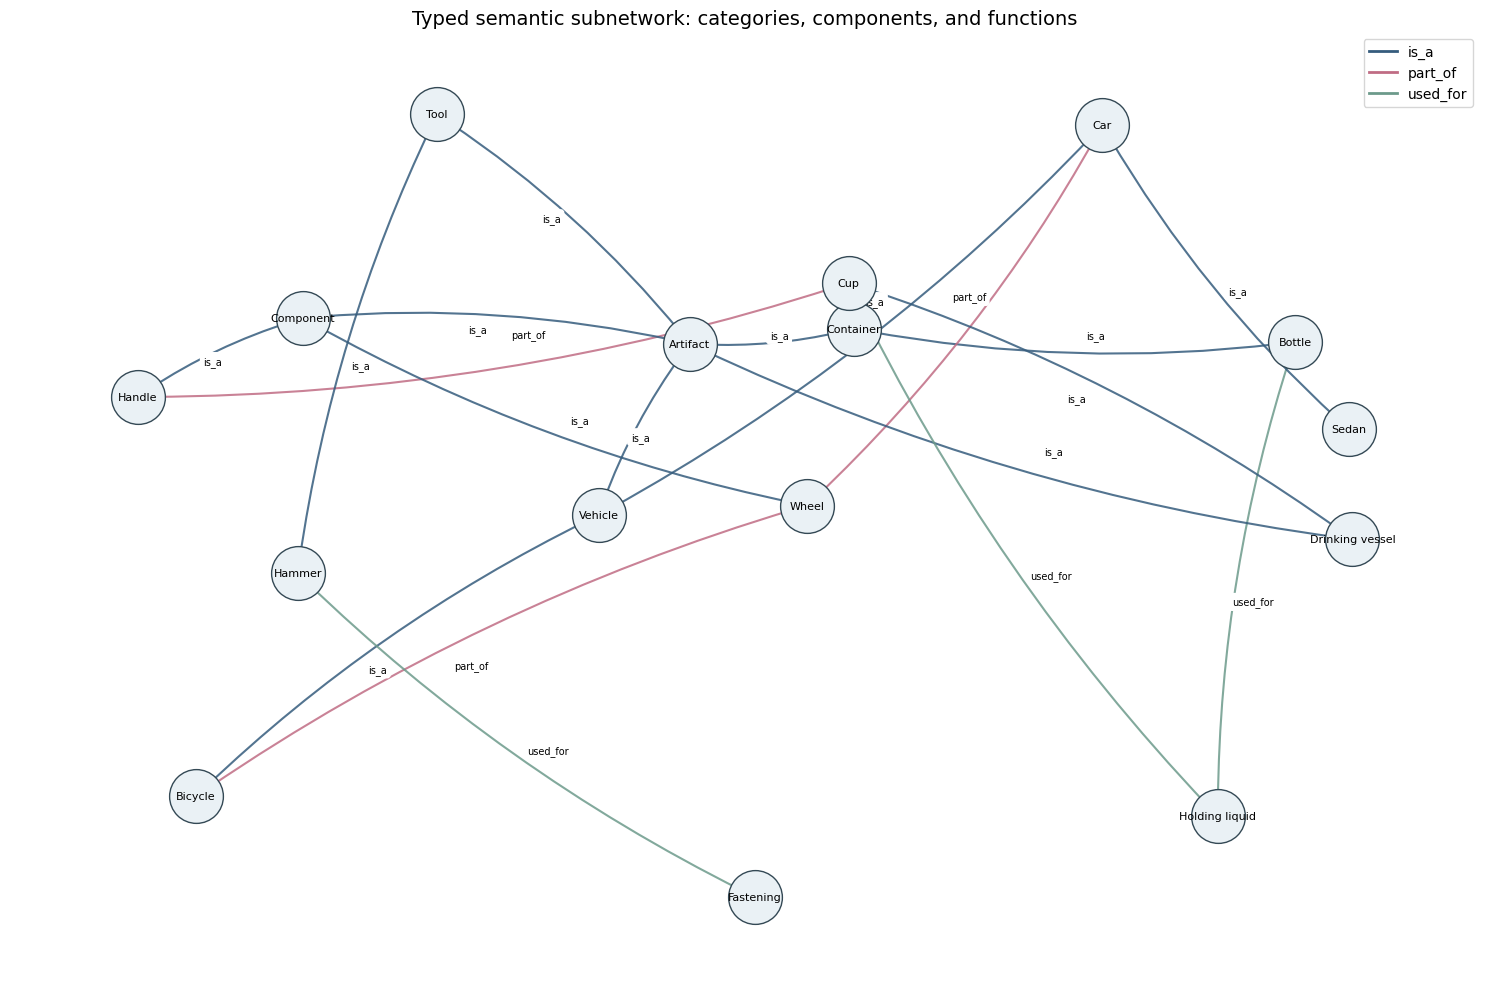

In [7]:
edge_colors = {
    "is_a": "#355C7D",
    "part_of": "#C06C84",
    "used_for": "#6C9A8B",
    "associated_with": "#D6A84F",
    "supports": "#8B78A6",
    "constrains": "#B35C44",
}
# Draw a compact object/function subnetwork so relation labels remain readable.
focus_nodes = ["artifact", "container", "cup", "bottle", "drinking_vessel", "vehicle", "car", "sedan", "bicycle", "tool", "hammer", "component", "handle", "wheel", "holding_liquid", "fastening"]
G_demo = G.subgraph(focus_nodes).copy()
colors = [edge_colors.get(G_demo[u][v]["relation"], "#777777") for u, v in G_demo.edges()]
full_pos = nx.spring_layout(G_demo, seed=17, k=1.1)
plt.figure(figsize=(15, 10))
nx.draw_networkx_nodes(G_demo, full_pos, node_size=1500, node_color="#eaf1f5", edgecolors="#344955")
nx.draw_networkx_labels(G_demo, full_pos, labels={n:G_demo.nodes[n]["label"] for n in G_demo.nodes}, font_size=8)
nx.draw_networkx_edges(G_demo, full_pos, edge_color=colors, arrows=True, arrowsize=13, alpha=.85, width=1.5, connectionstyle="arc3,rad=0.08")
edge_labels = {(u,v): d["relation"] for u,v,d in G_demo.edges(data=True)}
nx.draw_networkx_edge_labels(G_demo, full_pos, edge_labels=edge_labels, font_size=7, rotate=False, label_pos=.55)
from matplotlib.lines import Line2D
legend = [Line2D([0],[0], color=c, lw=2, label=r) for r,c in edge_colors.items() if any(d['relation']==r for _,_,d in G_demo.edges(data=True))]
plt.legend(handles=legend, loc="best", frameon=True)
plt.title("Typed semantic subnetwork: categories, components, and functions", fontsize=14)
plt.axis("off"); plt.tight_layout(); plt.show()

## 4. Calculate specificity from graph structure

We use two transparent estimates. They are teaching proxies and must be interpreted relative to this selected graph.

1. **Normalized depth:** shortest number of `is_a` steps from the root, divided by the maximum depth in this dataset. More levels below the root produce a higher score.
2. **Inverse descendant score:** one minus the log-scaled number of narrower descendants divided by the maximum log-scaled descendant count. A node with many descendants receives a lower score; a leaf receives a higher score.

These metrics capture different things. Depth measures how many category steps separate a concept from the root; descendant count measures how many narrower categories are represented below it. Neither is a universal measure of conceptual specificity.

In [8]:
def specificity_table(taxonomy, root="concept"):
    depth = shortest_depths(taxonomy, root)
    reachable = list(depth)
    max_depth = max(depth.values()) if depth else 0
    descendants = {n: len(nx.descendants(taxonomy, n)) for n in reachable}
    max_desc = max(descendants.values()) if descendants else 0
    log_denom = np.log1p(max_desc) if max_desc > 0 else 1.0
    rows = []
    for n in reachable:
        s_depth = depth[n] / max_depth if max_depth else 0.0
        s_desc = 1 - (np.log1p(descendants[n]) / log_denom) if max_desc > 0 else 0.0
        rows.append({"id": n, "label": G.nodes[n]["label"], "depth": depth[n],
                     "descendants": descendants[n], "S_depth": s_depth,
                     "S_inverse_desc": s_desc, "S_mean": (s_depth+s_desc)/2})
    return pd.DataFrame(rows).sort_values(["depth", "label"]).reset_index(drop=True)

spec = specificity_table(T, ROOT)
display(spec.round(3))

,id,label,depth,descendants,S_depth,S_inverse_desc,S_mean
0,concept,Concept,0,46,0.0,0.000,0.000
1,abstract_concept,Abstract concept,1,20,0.2,0.209,0.205
2,physical_concept,Physical concept,1,17,0.2,0.249,0.225
3,spatial_concept,Spatial concept,1,6,0.2,0.495,0.347
4,artifact,Artifact,2,13,0.4,0.315,0.357
5,event,Event,2,3,0.4,0.640,0.520
6,function,Function,2,2,0.4,0.715,0.557
7,moral_concept,Moral concept,2,6,0.4,0.495,0.447
8,organism,Organism,2,2,0.4,0.715,0.557
9,physical_property,Physical property,2,2,0.4,0.715,0.557


In [9]:
# Compare concepts that intuitively occupy different levels of the hierarchy.
focus = ["entity" if "entity" in concept_ids else ROOT, "artifact", "vehicle", "car", "sedan", "cup", "justice", "fairness", "restitution"]
focus = [x for x in focus if x in set(spec.id)]
display(spec[spec.id.isin(focus)][["label","depth","descendants","S_depth","S_inverse_desc","S_mean"]].round(3))

,label,depth,descendants,S_depth,S_inverse_desc,S_mean
0,Concept,0,46,0.0,0.000,0.000
4,Artifact,2,13,0.4,0.315,0.357
23,Justice,3,2,0.6,0.715,0.657
30,Vehicle,3,3,0.6,0.640,0.620
34,Car,4,1,0.8,0.820,0.810
36,Cup,4,0,0.8,1.000,0.900
37,Fairness,4,0,0.8,1.000,0.900
43,Restitution,4,0,0.8,1.000,0.900
46,Sedan,5,0,1.0,1.000,1.000


**Instructor interpretation:** Scores are relative to the current graph. If the taxonomy is expanded with more intermediate categories, normalized depth changes. If many descendants are missing, descendant-based specificity changes. The score is not a fact about a concept independent of the dataset.

**Ask students:** Can `cup` be more specific than `car` under one measure and less specific under another? What does that disagreement tell us about the metrics and the graph?

## 5. Inspect WordNet (optional live access)

The local course dataset is sufficient for the seminar. If the NLTK WordNet corpus has already been downloaded, the following cell can retrieve live synsets, definitions, hypernyms, and hyponyms. The cell does **not** attempt an internet download, so the notebook remains safe to run offline.

In [10]:
try:
    from nltk.corpus import wordnet as wn
    wn.ensure_loaded()
    WORDNET_AVAILABLE = True
    print("NLTK WordNet corpus is available.")
except Exception as exc:
    WORDNET_AVAILABLE = False
    print("NLTK WordNet corpus not available locally.")
    print("The class can continue with the supplied CSV taxonomy.")
    print("Optional preparation before class: in a connected environment run nltk.download('wordnet').")

NLTK WordNet corpus not available locally.
The class can continue with the supplied CSV taxonomy.
Optional preparation before class: in a connected environment run nltk.download('wordnet').


In [11]:
if WORDNET_AVAILABLE:
    for lemma in ["vehicle", "car", "cup", "person", "justice"]:
        synsets = wn.synsets(lemma, pos=wn.NOUN)
        print(f"\n{lemma}: {len(synsets)} noun synset(s)")
        for syn in synsets[:2]:
            print(" ", syn.name(), "—", syn.definition())
            print("    hypernyms:", [h.name() for h in syn.hypernyms()[:4]])
            print("    hyponyms:", [h.name() for h in syn.hyponyms()[:4]])
else:
    display(wordnet_targets)

,lemma,pos,student_prompt
0,vehicle,n,Inspect multiple senses; select the transport-...
1,car,n,Compare the selected sense with vehicle and se...
2,sedan,n,Inspect available hypernyms; discuss resource ...
3,cup,n,Compare container and drinking-vessel-like rel...
4,container,n,Inspect hypernyms and hyponyms.
5,person,n,Compare person with organism and group.
6,justice,n,Check whether the resource covers abstract/mor...
7,honesty,n,Inspect definitions and category relations; no...


## 6. Frame semantics: a small local teaching extract

WordNet organizes lexical concepts and category relations. Frame semantics instead represents a situation and the participant roles that make it understandable. The local CSV contains simplified classroom summaries of frames and selected roles. It is not a complete or verbatim FrameNet download.

In [12]:
display(framenet_examples)

,frame,frame_description,selected_roles,example_sentence,note
0,Commerce_buy,"A buyer obtains goods from a seller, typically...",Buyer; Seller; Goods; Money,The buyer paid the seller for the bicycle.,Simplified teaching summary of frame semantics...
1,Giving,A donor transfers an item to a recipient.,Donor; Recipient; Theme,The donor gave the book to the student.,Simplified teaching summary; use to distinguis...
2,Motion,"An entity moves along a path, potentially from...",Theme; Source; Goal; Path,The cyclist moved from the park to the station...,Simplified teaching summary; not a complete of...
3,Placing,An agent puts an item at a location.,Agent; Theme; Goal; Place,The student placed the cup on the table.,Simplified teaching summary; illustrates event...
4,Assistance,An agent helps another participant with an act...,Helper; Benefited_party; Goal,The colleague helped the team complete the task.,Simplified teaching summary; role names are cl...


**Compare the two resources:** In a category hierarchy, `car → vehicle` asks what kind of thing a car is. In a frame example, `buyer`, `seller`, `goods`, and `money` help describe a buying situation. A frame role is not a taxonomic parent. This distinction matters when designing typed edges in a semantic graph.

## 7. Perturb the graph: what happens when an edge is missing?

A semantic dataset is never automatically complete. Remove a category edge and recompute reachability and specificity. In this teaching graph, `cup` has two category parents, so removing one route may leave another route intact. This is a useful demonstration of multiple inheritance.

In [13]:
T_missing = T.copy()
edge_to_remove = ("artifact", "container")
T_missing.remove_edge(*edge_to_remove)
spec_missing = specificity_table(T_missing, ROOT)

before = spec.set_index("id")
after = spec_missing.set_index("id")
comparison_ids = ["cup", "bottle", "container", "vehicle", "car"]
rows=[]
for node in comparison_ids:
    rows.append({
        "concept": G.nodes[node]["label"],
        "reachable_before": node in before.index,
        "reachable_after": node in after.index,
        "S_depth_before": before.loc[node,"S_depth"] if node in before.index else np.nan,
        "S_depth_after": after.loc[node,"S_depth"] if node in after.index else np.nan,
        "S_inverse_desc_before": before.loc[node,"S_inverse_desc"] if node in before.index else np.nan,
        "S_inverse_desc_after": after.loc[node,"S_inverse_desc"] if node in after.index else np.nan,
    })
display(pd.DataFrame(rows).round(3))
print("Removed edge:", edge_to_remove)

,concept,reachable_before,reachable_after,S_depth_before,S_depth_after,S_inverse_desc_before,S_inverse_desc_after
0,Cup,True,True,0.8,0.8,1.000,1.000
1,Bottle,True,False,0.8,NaN,1.000,NaN
2,Container,True,False,0.6,NaN,0.715,NaN
3,Vehicle,True,True,0.6,0.6,0.640,0.636
4,Car,True,True,0.8,0.8,0.820,0.818


Removed edge: ('artifact', 'container')


**Expected observation:** removing `artifact → container` disconnects `bottle` from the root, but `cup` can remain reachable through `artifact → drinking_vessel → cup`. This illustrates why multiple inheritance can make a network more robust to a single missing edge. It does not prove the second parent is correct; that remains a data/ontology decision.

## 8. Student extension: add one well-justified relation

Ask each team to add 3–5 concepts from its Class 1–2 inventory and at least five typed edges. Each edge must have a type, a direction, and a short justification. Keep `is_a` edges separate from all other relation types.

In [14]:
# INSTRUCTOR DEMONSTRATION: create a small team extension in memory.
team_nodes = [
    ("scooter", "Scooter", "A small motor vehicle.", "physical"),
    ("electric_scooter", "Electric scooter", "A scooter powered by an electric motor.", "physical"),
]
G_team = G.copy()
for node_id, label, definition, domain in team_nodes:
    G_team.add_node(node_id, label=label, definition=definition, domain=domain)
G_team.add_edge("vehicle", "scooter", relation="is_a", provenance="team_extension", confidence="medium")
G_team.add_edge("scooter", "electric_scooter", relation="is_a", provenance="team_extension", confidence="medium")
assert nx.is_directed_acyclic_graph(nx.DiGraph((u,v) for u,v,d in G_team.edges(data=True) if d.get("relation")=="is_a"))
print("Extension added. Team should justify whether scooter belongs under vehicle in this dataset.")

Extension added. Team should justify whether scooter belongs under vehicle in this dataset.


## 9. Exit ticket and seminar submission

Each team submits:
1. A CSV/JSON edge list with 15–25 concepts (or a justified extension of the supplied graph).
2. A NetworkX visualization with a legend for relation types.
3. At least two specificity estimates, with explicit definitions.
4. One perturbation experiment (edge added, removed, or changed).
5. A 150–250 word interpretation: one useful result, one limitation, and one piece of evidence needed before making a stronger claim.

**Exit-ticket questions:**
- Which relation type was easiest to annotate? Which was ambiguous?
- What changed when you perturbed the graph?
- Why is graph depth not the same as human-perceived specificity?
- What part of embodied meaning is missing from your graph?

## 10. Instructor answer key / key points

- `is_a` edges should be broad-to-narrow; the taxonomy-only subgraph should be a DAG.
- Non-taxonomic relations must not be used in the category-depth calculation.
- The `cup` node has multiple parents in the prepared graph. Its position illustrates multiple inheritance.
- `S_depth` and `S_inverse_desc` are relative, graph-dependent proxies. Their differences are analytically useful, not errors to hide.
- Missing edges can disconnect nodes or alter descendant counts and normalized scores.
- WordNet is a lexical database; FrameNet organizes situations and participant roles. Neither is a complete representation of meaning.
- A graph can encode affordances, roles, and relations, but a semantic graph alone does not demonstrate perception, bodily grounding, action competence, or human-like understanding.

### Suggested debrief
Bring the conversation back to the course's later tasks: image schemas (Class 4), metaphor mappings (Class 5), embedding comparisons (Class 6), compression (Class 7), and embodied-AI evaluation (Class 9). Today's graph becomes a reusable data structure for those later activities.